# 08 - Self-play: learning a game by playing yourself

A **two-player zero-sum game**: whatever one player wins, the other loses. To learn it with RL we need an opponent - but a fixed,
hand-made opponent only teaches you to beat *that* opponent, and a perfect one does not exist.

**Self-play**: the agent plays against **copies of itself**. As it improves, so does its opponent - an automatic curriculum where the
opponent is always about as strong as you are. No search, no lookahead, no hand-made strategy: just RL against yourself.

The game is a hand-made two-player **Pong**, simulated like VMAS in notebook 07: thousands of games at once as tensors.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from marl.analysis import load_run, plot_matrix
from marl.selfplay import *
from marl.common.pong import random_policy, follow_ball_policy
from marl.pong_render import play_game
from marl.render import show_video
plt.rcParams["figure.dpi"] = 90
run = load_run("pong_selfplay_pool")

## 1. The game as an MDP (one for each player)

In [2]:
print_pong_mdp()

PLAYERS: 2 (left, right) - zero-sum. One network plays both sides.

OBSERVATION (9 numbers per player, MIRRORED: every player sees itself on the left)
#  feature            scaling              
0  own paddle y       x2 -> [-0.8, 0.8]    
1  opponent paddle y  x2                   
2  ball x             [-1, 1], own side < 0
3  ball y             x2 -> [-1, 1]        
4  ball vx            / 0.06 (max speed)   
5  ball vy            / 0.06               
6  own score          / 5                  
7  opponent score     / 5                  
8  time               step / step limit    

ACTIONS (discrete, both players move at the same time)
#  action                            
0  down    paddle moves 0.02 per step
1  stay                              
2  up      paddle moves 0.02 per step

REWARD (zero-sum)
event                    reward
you score a point        +1    
opponent scores a point  -1    
anything else            0     

EPISODE: first to 5 points, or 2000 steps (then the h

* **Mirrored observations**: the right player's view is flipped left-right, so both players see themselves on the left.
  The two seats are then *the same problem*, and **one network can play both sides**.
* The ball gets faster with every hit and the return angle depends on where it hits the paddle. Chasing the ball is not enough:
  a good player **aims** steep returns that the opponent cannot reach in time.

Two untrained (random) players:

In [3]:
frames, stats = play_game(random_policy, random_policy, names=("random", "random"), seed=1)
print(stats)
show_video(frames, fps=30, width=640)

{'score': [0.0, 5.0], 'steps': 635, 'hits': 6}


## 2. The self-play algorithm

One **actor** (policy) and one **critic** (value), shared by both seats, trained with PPO. Every training iteration:

1. **Pick opponents.** 2048 games run in parallel. In each game the learner takes a random seat. Its opponent is
   * its **current self** in 50% of the games,
   * otherwise a **past snapshot** drawn from the **opponent pool** (8 different snapshots per iteration).
2. **Play** 128 steps in every game. Both seats choose actions from their own (mirrored) observation; finished games restart.
3. **Learn** with PPO from the **learner's moves only** (in games against the current self, both seats are the learner).
   Reward: +1 / -1 per point, advantages with GAE.
4. **Every 90 s of training**: evaluate, save a snapshot, record two clips (the agent against itself, and against a bot), and
   **add the snapshot to the pool**.

Why a pool instead of only playing the current self? Playing only your latest self can chase its own tail: you learn to beat the
opponent's current trick, it learns a new one, and you may *forget* how to beat old tricks. Mixing in past selves keeps the old
lessons alive.

**Yardsticks** (never used for training): a **random** player and a scripted **follow-the-ball bot** that moves its paddle towards the ball.

In [4]:
describe_selfplay_networks(run)

network         layers                hidden act.  output                                     params
actor (policy)  9 -> 128 -> 128 -> 3  ReLU         3 logits -> softmax over {down, stay, up}  18,179
critic V(obs)   9 -> 128 -> 128 -> 1  ReLU         1 number: expected future reward           17,921

PPO: 2048 games in parallel x 128 steps per update, 4 epochs, minibatch 8192, lr 0.0003, gamma 0.99, GAE lambda 0.95, clip 0.2, entropy bonus 0.002
opponents: 50% of games vs the current self, the rest vs 8 past snapshots drawn from the pool


## 3. Training

374M game steps in 25 minutes of training


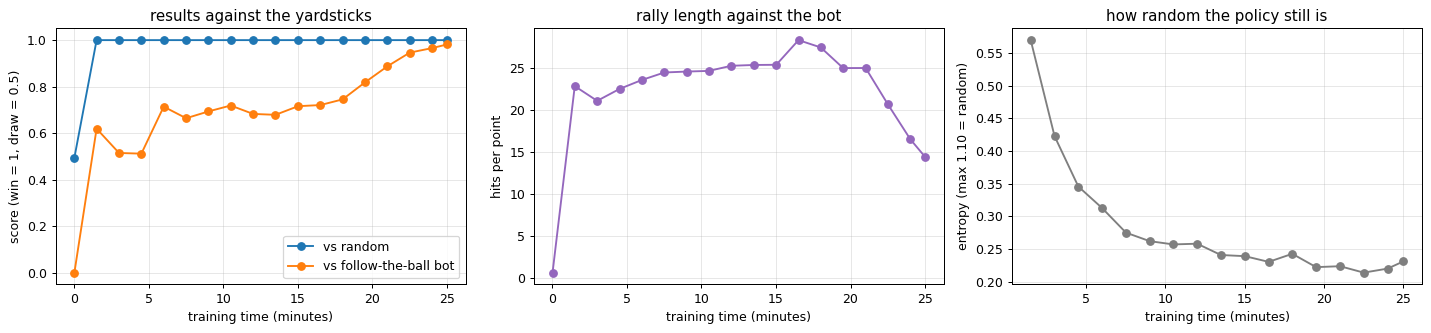

In [5]:
log = run["log"]
t = log["train_time"] / 60
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(t, log["score_vs_random"], "o-", label="vs random"); ax[0].plot(t, log["score_vs_bot"], "o-", label="vs follow-the-ball bot")
ax[0].set_ylabel("score (win = 1, draw = 0.5)"); ax[0].set_title("results against the yardsticks"); ax[0].legend()
ax[1].plot(t, log["rally_vs_bot"], "o-", color="tab:purple"); ax[1].set_ylabel("hits per point"); ax[1].set_title("rally length against the bot")
ax[2].plot(t[1:], log["entropy"][1:], "o-", color="tab:gray"); ax[2].set_ylabel("entropy (max 1.10 = random)"); ax[2].set_title("how random the policy still is")
for a in ax: a.set_xlabel("training time (minutes)"); a.grid(alpha=0.3)
plt.tight_layout()
print(f"{log['step'][-1] / 1e6:.0f}M game steps in {log['train_time'][-1] / 60:.0f} minutes of training")

Random is beaten within the first evaluation. Against the bot the agent wins about 70% for most of training, and only near the end
climbs to almost 100%. The bot is a fixed yardstick, though: the real question is whether the agent keeps getting better **against itself**.

## 4. Watching self-play evolve

The agent playing **against itself** at different stages of training (both paddles are the same snapshot):

In [6]:
import numpy as np
steps = run["log"]["step"][1:]                                    # snapshots after the untrained one
idx = sorted(set(np.linspace(0, len(steps) - 1, 3).round().astype(int)))   # up to 3 different snapshots
early, middle, late = (int(steps[idx[min(k, len(idx) - 1)]]) for k in range(3))
print(f"early: {early / 1e6:.0f}M steps")
show_video(str(snapshot_clip(run, early, "self")), width=640)

early: 32M steps


In [7]:
print(f"middle: {middle / 1e6:.0f}M steps")
show_video(str(snapshot_clip(run, middle, "self")), width=640)

middle: 223M steps


In [8]:
print(f"late: {late / 1e6:.0f}M steps")
show_video(str(snapshot_clip(run, late, "self")), width=640)

late: 374M steps


**Does each new generation beat the previous one?** That is what self-play promises: the agent keeps finding ways to beat
its own past. Below, generations from the untrained network to the final agent, each playing **the generation before it**.
A point between good players can take a long rally, so we show **point replays** - the last seconds before each of the first
three points (fewer if the rallies get so long that the game hits its step limit) - and print the newer generation's
score over 256 full games.

In [9]:
frames, rows = generation_ladder(run, k=5, points=3)
for new, old, won, n, score in rows:
    print(f"{new:>5} vs {old:>5}:  replays {won}/{n} points to the newer one  |  over 256 games the newer one scores {score:.2f}")
show_video(frames, fps=30, width=640)

  32M vs    0M:  replays 3/3 points to the newer one  |  over 256 games the newer one scores 1.00
 138M vs   32M:  replays 2/3 points to the newer one  |  over 256 games the newer one scores 0.75
 223M vs  138M:  replays 1/1 points to the newer one  |  over 256 games the newer one scores 0.50
 294M vs  223M:  replays 2/2 points to the newer one  |  over 256 games the newer one scores 0.65
 374M vs  294M:  replays 3/3 points to the newer one  |  over 256 games the newer one scores 0.84


Mostly yes - with one exception: in the middle of training a new generation is only *even* with the previous one (0.50).
That is the **plateau** you will see in the tournament below; the progress after it comes from a new way of playing (section 6).

## 5. Is a later self a better self? A tournament

Every pair of players (12 snapshots + random + bot) plays 256 games, seats swapped half the time. From all results we fit
**Elo ratings** (the chess rating system: a 200-point gap means the stronger player scores ~0.76).

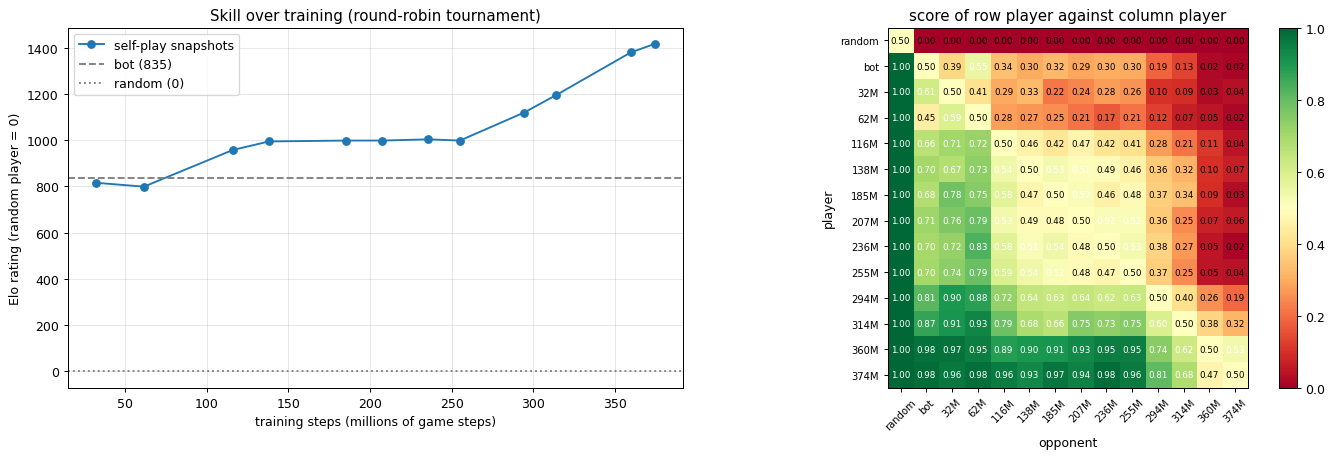

In [10]:
tour, style = load_selfplay_summary(run)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
plot_elo(tour, ax[0])
plot_matrix(tour["S"], tour["names"], ax=ax[1], title="score of row player against column player", xlabel="opponent",
            ylabel="player", cmap="RdYlGn")
plt.tight_layout()

Read the matrix row by row: later snapshots (lower rows) beat earlier ones (left columns). Progress is **not smooth**:
* early on the agent quickly passes the bot's level,
* then a long **plateau**: the snapshots in the middle of training are roughly 50/50 against each other,
* then a **breakthrough** near the end: the final agent beats every earlier version of itself 93-98% of the time.

What changed? Look at *how* it plays.

## 6. What did it learn?
The playing style of every snapshot against the bot: how often its returns are **steep** (more than 30 degrees), and how many hits a point takes.

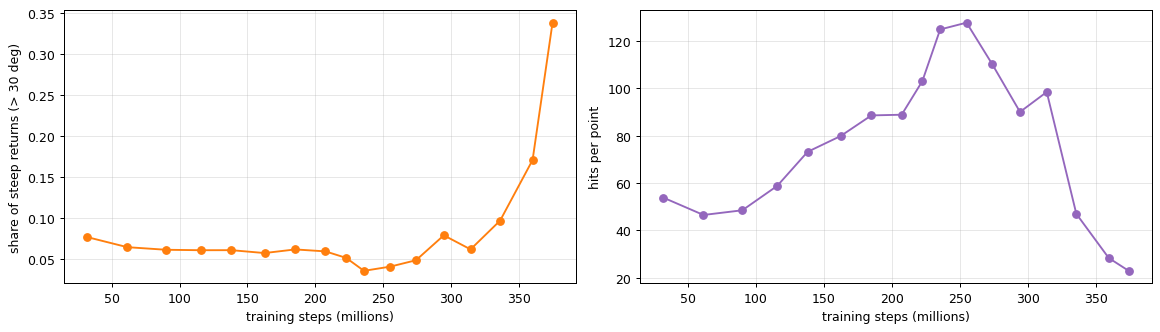

In [11]:
trained = style["step"] > 0                                   # the untrained snapshot almost never hits the ball
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(style["step"][trained] / 1e6, style["steep_share"][trained], "o-", color="tab:orange"); ax[0].set_ylabel("share of steep returns (> 30 deg)")
ax[1].plot(style["step"][trained] / 1e6, style["hits_per_point"][trained], "o-", color="tab:purple"); ax[1].set_ylabel("hits per point")
for a in ax: a.set_xlabel("training steps (millions)"); a.grid(alpha=0.3)
plt.tight_layout()

Two phases:
1. **Defence**: returns stay flat, but points get longer and longer - the agent learns to return almost everything
   (against an opponent that is learning the same).
2. **Attack**: steep returns suddenly become common and points end quickly - the agent has discovered **aiming** the ball where the
   opponent cannot reach it in time. This is exactly when the Elo rating breaks out of its plateau.

Nobody programmed either strategy. Attack only pays off once defence is good - and the opponent that made defence good was the agent itself.

A point between good players can take a long rally (hundreds of steps), so instead of whole games we show **point replays**:
the last few seconds before each of the first three points.

**The final agent against the follow-the-ball bot** - watch the last return before each point:

In [12]:
from marl.pong_render import point_replays
early, final = load_snapshot(run["ckpts"][1]), load_snapshot(run["ckpts"][-1])
frames, scorers = point_replays(final, follow_ball_policy, names=(f"agent, final ({final.name})", "follow-the-ball bot"), seed=0)
print("points won by:", scorers)
show_video(frames, fps=30, width=640)

points won by: ['agent, final (374M)', 'agent, final (374M)', 'agent, final (374M)']


**An early agent against the same bot** - it returns the ball, but does not yet aim:

In [13]:
frames, scorers = point_replays(early, follow_ball_policy, names=(f"agent, early ({early.name})", "follow-the-ball bot"), seed=0)
print("points won by:", scorers)
show_video(frames, fps=30, width=640)

points won by: ['agent, early (32M)', 'agent, early (32M)', 'follow-the-ball bot']


**The final agent against its early self:**

In [14]:
frames, scorers = point_replays(final, early, names=(f"final ({final.name})", f"early ({early.name})"), seed=3)
print("points won by:", scorers)
show_video(frames, fps=30, width=640)

points won by: ['final (374M)', 'final (374M)', 'final (374M)']


## Takeaways
* **Self-play** turns a two-player game into a learning problem with no hand-made opponent: the opponent is always the agent itself.
* It is an **automatic curriculum**: easy opponents early, harder ones as the agent improves - progress is visible as rising Elo.
* The opponent keeps changing, so the problem is **non-stationary** (as in notebooks 02-03); an **opponent pool** of past selves keeps
  old lessons from being forgotten.
* Fixed yardsticks (random, a scripted bot) are quickly beaten; **ratings from playing against past selves** keep measuring progress.
* Further: AlphaZero combines self-play with lookahead search - the same idea of learning from games against yourself.